
# Retail Sales Performance Analysis

### Exploratory Data Analysis and Business Intelligence with Python

---

## 1. Project Overview

This project explores retail transaction data to identify sales trends, evaluate product performance, and generate business insights using Python.

The analysis focuses on transforming raw transactional data into meaningful business information through data exploration, statistical analysis, and visualization.

## 2. Business Objectives

- Evaluate overall sales and revenue performance.
- Identify high-performing products and categories.
- Analyze regional sales distribution.
- Examine customer purchasing patterns.
- Investigate sales trends over time.
- Calculate key business performance indicators (KPIs).

## 3. Dataset Description

The project uses a reproducible synthetic retail transaction dataset containing 1,500 transactions across the 2024–2025 period.

The dataset includes transaction details, customer identifiers, geographical information, product categories, pricing, discounts, and revenue metrics.

## 4. Technologies

- Python 3
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 5. Analytical Workflow

1. Data loading and inspection
2. Data quality assessment
3. Data cleaning and preparation
4. Exploratory data analysis
5. Business KPI calculation
6. Sales performance visualization
7. Business insights and conclusions

---

**Project:** Retail Sales Performance Analysis  
**Data classification:** Synthetic demonstration data  
**Analysis period:** 2024–2025


In [1]:

# Import the required libraries

import pandas as pd
import numpy as np

# Configure Pandas display options

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Locate the retail sales dataset

from pathlib import Path

possible_paths = [
    Path("data/raw/retail_sales.csv"),
    Path("../data/raw/retail_sales.csv"),
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Retail sales dataset not found. "
        "Please verify the data/raw directory."
    )

# Load the dataset

sales_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["order_date"]
)

print("Dataset loaded successfully!")
print(f"Dataset location: {DATA_PATH.resolve()}")
print(f"Total transactions: {len(sales_df):,}")
print(f"Total columns: {len(sales_df.columns)}")


Dataset loaded successfully!
Dataset location: D:\Users\NoteBook\Desktop\retail-sales-performance-analysis\data\raw\retail_sales.csv
Total transactions: 1,500
Total columns: 16



## 6. Initial Data Exploration

This section examines the dataset's structure, dimensions, data types, and overall quality before performing any transformations.


In [2]:
sales_df.head()

,order_id,order_date,customer_id,region,city,sales_channel,product_id,product_name,category,unit_price,quantity,discount_pct,gross_revenue,discount_amount,net_revenue,payment_method
0,ORD-000583,2024-01-01,C0032,South,New York,Physical Store,P002,Laptop,Electronics,1199.0,1,0.00,1199.0,0.0,1199.0,Credit Card
1,ORD-001260,2024-01-01,C0199,South,New York,Online,P013,Dumbbell Set,Sports & Outdoors,75.0,1,0.00,75.0,0.0,75.0,Credit Card
2,ORD-000962,2024-01-02,C0290,North,Montreal,Online,P007,Air Fryer,Home & Kitchen,129.0,1,0.00,129.0,0.0,129.0,Debit Card
3,ORD-000191,2024-01-02,C0247,West,Vancouver,Physical Store,P011,Jacket,Clothing,110.0,1,0.05,110.0,5.5,104.5,Credit Card
4,ORD-000670,2024-01-03,C0198,West,Vancouver,Physical Store,P003,Headphones,Electronics,149.0,2,0.00,298.0,0.0,298.0,Credit Card


In [3]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         1500 non-null   str           
 1   order_date       1500 non-null   datetime64[us]
 2   customer_id      1500 non-null   str           
 3   region           1500 non-null   str           
 4   city             1500 non-null   str           
 5   sales_channel    1500 non-null   str           
 6   product_id       1500 non-null   str           
 7   product_name     1500 non-null   str           
 8   category         1500 non-null   str           
 9   unit_price       1500 non-null   float64       
 10  quantity         1500 non-null   int64         
 11  discount_pct     1500 non-null   float64       
 12  gross_revenue    1500 non-null   float64       
 13  discount_amount  1500 non-null   float64       
 14  net_revenue      1500 non-null   float64       
 15

In [4]:
missing_values = sales_df.isnull().sum()

print("MISSING VALUES BY COLUMN")
print("-" * 35)
print(missing_values)

print(f"\nTotal missing values: {missing_values.sum()}")

MISSING VALUES BY COLUMN
-----------------------------------
order_id           0
order_date         0
customer_id        0
region             0
city               0
sales_channel      0
product_id         0
product_name       0
category           0
unit_price         0
quantity           0
discount_pct       0
gross_revenue      0
discount_amount    0
net_revenue        0
payment_method     0
dtype: int64

Total missing values: 0


In [5]:
duplicate_count = sales_df.duplicated().sum()

print(f"Duplicate transactions: {duplicate_count}")

Duplicate transactions: 0


In [6]:
sales_df.describe().round(2)

,order_date,unit_price,quantity,discount_pct,gross_revenue,discount_amount,net_revenue
count,1500,1500.00,1500.0,1500.00,1500.00,1500.00,1500.00
mean,2024-12-31 03:36:00,209.85,2.0,0.05,412.24,20.45,391.80
min,2024-01-01 00:00:00,18.00,1.0,0.00,18.00,0.00,14.40
25%,2024-06-29 18:00:00,45.00,1.0,0.00,75.00,0.00,75.00
50%,2025-01-10 00:00:00,95.00,2.0,0.05,150.00,1.80,149.00
75%,2025-07-03 00:00:00,169.00,3.0,0.10,376.25,15.00,342.00
max,2025-12-31 00:00:00,1199.00,5.0,0.20,5995.00,959.20,5995.00
std,NaN,309.52,1.1,0.06,708.68,61.75,673.47



## 7. Data Quality Assessment

Before conducting business analysis, the dataset must be evaluated for completeness, consistency, and validity.

This section performs a series of data quality checks to identify:

- Missing values
- Duplicate transactions
- Invalid dates
- Incorrect numerical values
- Invalid discount rates
- Inconsistent revenue calculations

The objective is to establish whether the dataset is suitable for further analysis.


In [7]:

# DATA QUALITY ASSESSMENT

quality_checks = []

def add_check(check_name, passed, details):
    """Record the result of a data quality check."""

    quality_checks.append({
        "Check": check_name,
        "Status": "PASS" if passed else "FAIL",
        "Details": details
    })


# 1. Missing values

missing_count = sales_df.isnull().sum().sum()

add_check(
    "Missing values",
    missing_count == 0,
    f"{missing_count} missing values detected"
)


# 2. Duplicate transactions

duplicate_rows = sales_df.duplicated().sum()

add_check(
    "Duplicate rows",
    duplicate_rows == 0,
    f"{duplicate_rows} duplicate rows detected"
)


# 3. Unique order identifiers

duplicate_ids = sales_df["order_id"].duplicated().sum()

add_check(
    "Unique order IDs",
    duplicate_ids == 0,
    f"{duplicate_ids} duplicate order IDs detected"
)


# 4. Valid transaction dates

invalid_dates = sales_df["order_date"].isna().sum()

add_check(
    "Valid transaction dates",
    invalid_dates == 0,
    f"{invalid_dates} invalid dates detected"
)


# 5. Positive product prices

invalid_prices = (sales_df["unit_price"] <= 0).sum()

add_check(
    "Positive unit prices",
    invalid_prices == 0,
    f"{invalid_prices} invalid prices detected"
)


# 6. Positive quantities

invalid_quantities = (sales_df["quantity"] <= 0).sum()

add_check(
    "Positive quantities",
    invalid_quantities == 0,
    f"{invalid_quantities} invalid quantities detected"
)


# 7. Valid discount percentages

invalid_discounts = (
    (sales_df["discount_pct"] < 0) |
    (sales_df["discount_pct"] > 1)
).sum()

add_check(
    "Valid discount rates",
    invalid_discounts == 0,
    f"{invalid_discounts} invalid discount rates detected"
)


# 8. Non-negative revenue

negative_revenue = (sales_df["net_revenue"] < 0).sum()

add_check(
    "Non-negative revenue",
    negative_revenue == 0,
    f"{negative_revenue} negative revenue values detected"
)


# 9. Gross revenue calculation

expected_gross = (
    sales_df["unit_price"] * sales_df["quantity"]
)

gross_matches = np.isclose(
    expected_gross,
    sales_df["gross_revenue"],
    atol=0.01,
    rtol=0
)

add_check(
    "Gross revenue consistency",
    gross_matches.all(),
    f"{(~gross_matches).sum()} inconsistent records"
)


# 10. Discount calculation

expected_discount = (
    sales_df["gross_revenue"] *
    sales_df["discount_pct"]
).round(2)

discount_matches = np.isclose(
    expected_discount,
    sales_df["discount_amount"],
    atol=0.01,
    rtol=0
)

add_check(
    "Discount calculation consistency",
    discount_matches.all(),
    f"{(~discount_matches).sum()} inconsistent records"
)


# 11. Net revenue calculation

expected_net = (
    sales_df["gross_revenue"] -
    sales_df["discount_amount"]
).round(2)

net_matches = np.isclose(
    expected_net,
    sales_df["net_revenue"],
    atol=0.01,
    rtol=0
)

add_check(
    "Net revenue consistency",
    net_matches.all(),
    f"{(~net_matches).sum()} inconsistent records"
)


# DISPLAY THE QUALITY REPORT

quality_report = pd.DataFrame(quality_checks)

display(quality_report)

failed_checks = (
    quality_report["Status"] == "FAIL"
).sum()

print("=" * 55)
print("DATA QUALITY ASSESSMENT SUMMARY")
print("=" * 55)

print(f"Total checks: {len(quality_report)}")
print(f"Passed checks: {(quality_report['Status'] == 'PASS').sum()}")
print(f"Failed checks: {failed_checks}")

if failed_checks == 0:
    print("\nAll data quality checks passed successfully!")
else:
    print("\nAttention: Some data quality issues require investigation.")


,Check,Status,Details
0,Missing values,PASS,0 missing values detected
1,Duplicate rows,PASS,0 duplicate rows detected
2,Unique order IDs,PASS,0 duplicate order IDs detected
3,Valid transaction dates,PASS,0 invalid dates detected
4,Positive unit prices,PASS,0 invalid prices detected
5,Positive quantities,PASS,0 invalid quantities detected
6,Valid discount rates,PASS,0 invalid discount rates detected
7,Non-negative revenue,PASS,0 negative revenue values detected
8,Gross revenue consistency,PASS,0 inconsistent records
9,Discount calculation consistency,PASS,0 inconsistent records


DATA QUALITY ASSESSMENT SUMMARY
Total checks: 11
Passed checks: 11
Failed checks: 0

All data quality checks passed successfully!



## 8. Data Cleaning and Preparation

Following the initial data quality assessment, this section prepares the transaction dataset for business analysis.

The preparation process includes:

- Standardizing column names.
- Normalizing text values.
- Ensuring correct data types.
- Creating additional time-based analytical features.
- Exporting the prepared dataset separately.

The original raw dataset remains unchanged to preserve data integrity and reproducibility.


In [8]:

# DATA CLEANING AND PREPARATION

from pathlib import Path

# 1. Create a copy of the original dataset

clean_df = sales_df.copy()

print("Starting data preparation...")
print(f"Original dataset: {clean_df.shape}")


# 2. Standardize column names

clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


# 3. Normalize text columns

text_columns = clean_df.select_dtypes(
    include=["object"]
).columns

for column in text_columns:
    clean_df[column] = clean_df[column].str.strip()


# 4. Ensure correct data types

clean_df["order_date"] = pd.to_datetime(
    clean_df["order_date"],
    errors="raise"
)

numeric_columns = [
    "unit_price",
    "quantity",
    "discount_pct",
    "gross_revenue",
    "discount_amount",
    "net_revenue",
]

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="raise"
    )


# 5. Create analytical time features

clean_df["order_year"] = clean_df["order_date"].dt.year

clean_df["order_month"] = (
    clean_df["order_date"].dt.to_period("M").astype(str)
)

clean_df["order_quarter"] = (
    clean_df["order_date"].dt.to_period("Q").astype(str)
)


# 6. Verify the prepared dataset

assert clean_df["order_id"].is_unique
assert clean_df.isnull().sum().sum() == 0

assert np.isclose(
    clean_df["gross_revenue"],
    clean_df["unit_price"] * clean_df["quantity"],
    atol=0.01,
    rtol=0
).all()

assert np.isclose(
    clean_df["net_revenue"],
    clean_df["gross_revenue"] - clean_df["discount_amount"],
    atol=0.01,
    rtol=0
).all()


# 7. Export the prepared dataset

current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "data" / "raw" / "retail_sales.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root directory."
    )

processed_directory = project_root / "data" / "processed"

processed_directory.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    processed_directory / "retail_sales_cleaned.csv"
)

clean_df.to_csv(
    output_path,
    index=False,
    date_format="%Y-%m-%d"
)


# 8. Display preparation summary

print("\n" + "=" * 50)
print("DATA PREPARATION SUMMARY")
print("=" * 50)

print(f"Original records: {len(sales_df):,}")
print(f"Prepared records: {len(clean_df):,}")
print(f"Original columns: {len(sales_df.columns)}")
print(f"Prepared columns: {len(clean_df.columns)}")

print("\nNew analytical features:")
print("- order_year")
print("- order_month")
print("- order_quarter")

print("\nPrepared dataset saved successfully:")
print(output_path)

print("\nAll preparation checks passed!")


Starting data preparation...
Original dataset: (1500, 16)

DATA PREPARATION SUMMARY
Original records: 1,500
Prepared records: 1,500
Original columns: 16
Prepared columns: 19

New analytical features:
- order_year
- order_month
- order_quarter

Prepared dataset saved successfully:
d:\Users\NoteBook\Desktop\retail-sales-performance-analysis\data\processed\retail_sales_cleaned.csv

All preparation checks passed!


C:\Users\NoteBook\AppData\Local\Temp\ipykernel_18052\918873690.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = clean_df.select_dtypes(


In [9]:
clean_df.head()

,order_id,order_date,customer_id,region,city,sales_channel,product_id,product_name,category,unit_price,quantity,discount_pct,gross_revenue,discount_amount,net_revenue,payment_method,order_year,order_month,order_quarter
0,ORD-000583,2024-01-01,C0032,South,New York,Physical Store,P002,Laptop,Electronics,1199.0,1,0.00,1199.0,0.0,1199.0,Credit Card,2024,2024-01,2024Q1
1,ORD-001260,2024-01-01,C0199,South,New York,Online,P013,Dumbbell Set,Sports & Outdoors,75.0,1,0.00,75.0,0.0,75.0,Credit Card,2024,2024-01,2024Q1
2,ORD-000962,2024-01-02,C0290,North,Montreal,Online,P007,Air Fryer,Home & Kitchen,129.0,1,0.00,129.0,0.0,129.0,Debit Card,2024,2024-01,2024Q1
3,ORD-000191,2024-01-02,C0247,West,Vancouver,Physical Store,P011,Jacket,Clothing,110.0,1,0.05,110.0,5.5,104.5,Credit Card,2024,2024-01,2024Q1
4,ORD-000670,2024-01-03,C0198,West,Vancouver,Physical Store,P003,Headphones,Electronics,149.0,2,0.00,298.0,0.0,298.0,Credit Card,2024,2024-01,2024Q1


In [10]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         1500 non-null   str           
 1   order_date       1500 non-null   datetime64[us]
 2   customer_id      1500 non-null   str           
 3   region           1500 non-null   str           
 4   city             1500 non-null   str           
 5   sales_channel    1500 non-null   str           
 6   product_id       1500 non-null   str           
 7   product_name     1500 non-null   str           
 8   category         1500 non-null   str           
 9   unit_price       1500 non-null   float64       
 10  quantity         1500 non-null   int64         
 11  discount_pct     1500 non-null   float64       
 12  gross_revenue    1500 non-null   float64       
 13  discount_amount  1500 non-null   float64       
 14  net_revenue      1500 non-null   float64       
 15


## 9. Key Business Performance Indicators (KPIs)

Key Performance Indicators provide a quantitative overview of business performance.

This section calculates the primary financial and operational metrics derived from the prepared retail transaction dataset.

The following indicators will be evaluated:

- Total Net Revenue
- Total Orders
- Average Order Value (AOV)
- Total Units Sold
- Total Unique Customers
- Total Discounts Granted

These metrics establish a baseline for evaluating sales performance and identifying business trends.


In [11]:

# KEY BUSINESS PERFORMANCE INDICATORS

# 1. Total net revenue
total_revenue = clean_df["net_revenue"].sum()


# 2. Total orders
total_orders = clean_df["order_id"].nunique()


# 3. Average order value
average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)


# 4. Total units sold
total_units_sold = clean_df["quantity"].sum()


# 5. Total unique customers
total_customers = clean_df["customer_id"].nunique()


# 6. Total discounts granted
total_discounts = clean_df["discount_amount"].sum()


# BUILD KPI SUMMARY

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Net Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Total Unique Customers",
        "Total Discounts Granted"
    ],

    "Value": [
        f"${total_revenue:,.2f}",
        f"{total_orders:,}",
        f"${average_order_value:,.2f}",
        f"{total_units_sold:,}",
        f"{total_customers:,}",
        f"${total_discounts:,.2f}"
    ]
})


# DISPLAY KPI REPORT

print("=" * 50)
print("       RETAIL SALES PERFORMANCE SUMMARY")
print("=" * 50)

display(kpi_summary)

print("=" * 50)
print("KPI CALCULATION COMPLETED SUCCESSFULLY")


       RETAIL SALES PERFORMANCE SUMMARY


,Metric,Value
0,Total Net Revenue,"$587,697.55"
1,Total Orders,"1,500"
2,Average Order Value,$391.80
3,Total Units Sold,"2,998"
4,Total Unique Customers,298
5,Total Discounts Granted,"$30,668.45"


KPI CALCULATION COMPLETED SUCCESSFULLY


In [12]:

# KPI VALIDATION

assert total_orders == len(clean_df)

assert np.isclose(
    total_revenue,
    clean_df["net_revenue"].sum()
)

assert np.isclose(
    average_order_value,
    total_revenue / total_orders
)

assert total_units_sold == clean_df["quantity"].sum()

assert np.isclose(
    total_discounts,
    clean_df["discount_amount"].sum()
)

print("All KPI validation checks passed successfully.")


All KPI validation checks passed successfully.



## 10. Product Category Performance Analysis

This section evaluates sales performance across the different product categories.

The analysis focuses on:

- Revenue generated by each category.
- Number of transactions per category.
- Total units sold.
- Average transaction value.
- Revenue contribution by category.

The objective is to identify the strongest-performing product categories and understand their contribution to overall business revenue.


In [13]:

# PRODUCT CATEGORY PERFORMANCE ANALYSIS

category_performance = (
    clean_df.groupby("category")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        average_order_value=("net_revenue", "mean"),
        total_discounts=("discount_amount", "sum")
    )
    .reset_index()
)

# Calculate each category's contribution to total revenue

category_performance["revenue_contribution_pct"] = (
    category_performance["total_revenue"]
    / total_revenue * 100
)

# Sort categories by revenue

category_performance = (
    category_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Display the results

display(
    category_performance.style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "total_discounts": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


,category,total_revenue,total_orders,units_sold,average_order_value,total_discounts,revenue_contribution_pct
0,Electronics,"$412,398.55",367,719,"$1,123.70","$20,722.45",70.17%
1,Home & Kitchen,"$89,362.30",371,738,$240.87,"$4,639.70",15.21%
2,Sports & Outdoors,"$40,759.75",293,624,$139.11,"$2,540.25",6.94%
3,Clothing,"$33,627.25",284,538,$118.41,"$2,012.75",5.72%
4,Books,"$11,549.70",185,379,$62.43,$753.30,1.97%


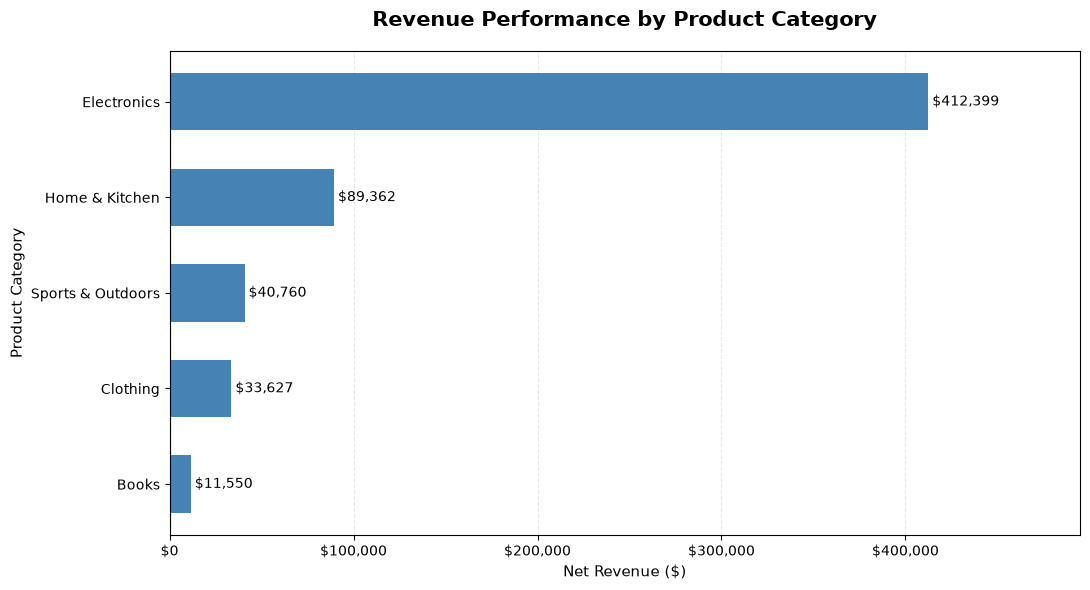

In [14]:

# REVENUE PERFORMANCE BY PRODUCT CATEGORY

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Prepare data for visualization

plot_data = category_performance.sort_values(
    "total_revenue",
    ascending=True
)

# Create the chart

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["category"],
    plot_data["total_revenue"],
    color="steelblue",
    height=0.6
)

# Add revenue labels

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" ${width:,.0f}",
        va="center",
        fontsize=10
    )

# Format the chart

ax.set_title(
    "Revenue Performance by Product Category",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Net Revenue ($)", fontsize=11)
ax.set_ylabel("Product Category", fontsize=11)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.set_xlim(0, plot_data["total_revenue"].max() * 1.2)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [15]:

# IDENTIFY THE TOP-PERFORMING CATEGORY

top_category = category_performance.iloc[0]

print("=" * 50)
print("TOP PRODUCT CATEGORY")
print("=" * 50)

print(f"Category: {top_category['category']}")
print(f"Net Revenue: ${top_category['total_revenue']:,.2f}")
print(f"Orders: {top_category['total_orders']:,}")
print(f"Units Sold: {top_category['units_sold']:,}")
print(
    f"Revenue Contribution: "
    f"{top_category['revenue_contribution_pct']:.2f}%"
)


TOP PRODUCT CATEGORY
Category: Electronics
Net Revenue: $412,398.55
Orders: 367
Units Sold: 719
Revenue Contribution: 70.17%



## 11. Regional Sales Performance Analysis

This section evaluates retail sales performance across the four geographical market groups represented in the dataset.

The analysis focuses on:

- Total revenue generated by each region.
- Number of transactions.
- Total units sold.
- Number of unique customers.
- Average order value.
- Regional contribution to total revenue.

The objective is to identify high-performing markets and compare regional sales performance.

**Data note:** Regional assignments are synthetic demonstration groupings and do not represent official geographical sales territories.


In [16]:

# REGIONAL SALES PERFORMANCE ANALYSIS

regional_performance = (
    clean_df.groupby("region")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        unique_customers=("customer_id", "nunique"),
        average_order_value=("net_revenue", "mean"),
        total_discounts=("discount_amount", "sum")
    )
    .reset_index()
)

# Calculate regional revenue contribution

regional_performance["revenue_contribution_pct"] = (
    regional_performance["total_revenue"]
    / total_revenue * 100
)

# Rank regions by revenue

regional_performance = (
    regional_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Display regional results

display(
    regional_performance.style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "total_discounts": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


,region,total_revenue,total_orders,units_sold,unique_customers,average_order_value,total_discounts,revenue_contribution_pct
0,West,"$169,704.35",379,774,210,$447.77,"$7,362.65",28.88%
1,North,"$153,587.00",388,751,217,$395.84,"$9,348.00",26.13%
2,East,"$134,149.10",353,698,205,$380.03,"$6,443.90",22.83%
3,South,"$130,257.10",380,775,214,$342.78,"$7,513.90",22.16%


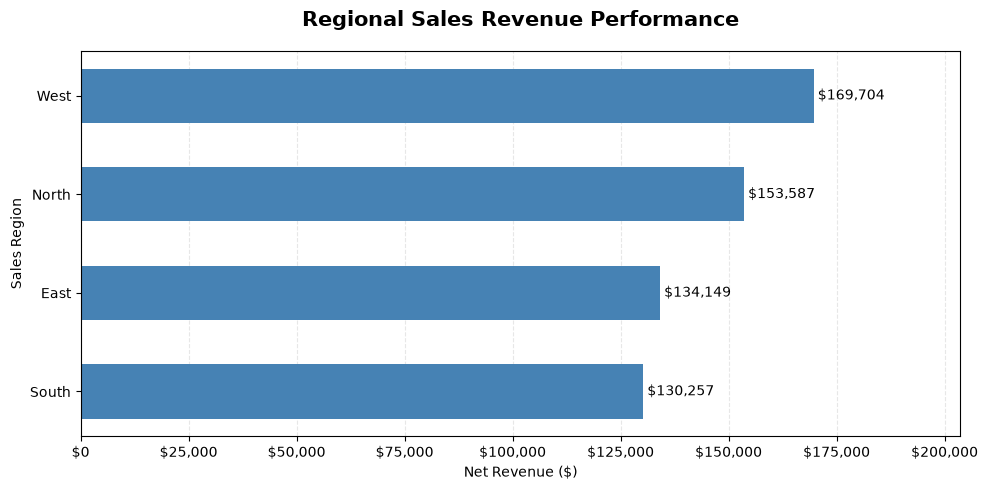

In [17]:

# REGIONAL REVENUE VISUALIZATION

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plot_data = regional_performance.sort_values(
    "total_revenue",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data["region"],
    plot_data["total_revenue"],
    height=0.55,
    color="steelblue"
)

# Add revenue labels

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" ${width:,.0f}",
        va="center",
        fontsize=10
    )

# Chart formatting

ax.set_title(
    "Regional Sales Revenue Performance",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Net Revenue ($)")
ax.set_ylabel("Sales Region")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.set_xlim(
    0,
    plot_data["total_revenue"].max() * 1.2
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [18]:

# IDENTIFY THE TOP-PERFORMING REGION

top_region = regional_performance.iloc[0]

print("=" * 50)
print("TOP-PERFORMING SALES REGION")
print("=" * 50)

print(f"Region: {top_region['region']}")
print(f"Net Revenue: ${top_region['total_revenue']:,.2f}")
print(f"Total Orders: {top_region['total_orders']:,}")
print(f"Units Sold: {top_region['units_sold']:,}")
print(f"Unique Customers: {top_region['unique_customers']:,}")

print(
    f"Revenue Contribution: "
    f"{top_region['revenue_contribution_pct']:.2f}%"
)


TOP-PERFORMING SALES REGION
Region: West
Net Revenue: $169,704.35
Total Orders: 379
Units Sold: 774
Unique Customers: 210
Revenue Contribution: 28.88%



## 12. Sales Trends and Time-Series Analysis

This section examines the evolution of retail sales performance over the 2024–2025 analysis period.

The analysis focuses on:

- Annual revenue comparisons.
- Monthly revenue trends.
- Quarterly sales performance.
- Transaction volume over time.
- Identification of high-performing periods.

The objective is to understand temporal changes in sales activity and evaluate the consistency of business performance.


In [19]:

# ANNUAL SALES PERFORMANCE

annual_performance = (
    clean_df.groupby("order_year")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

annual_performance["average_order_value"] = (
    annual_performance["total_revenue"]
    / annual_performance["total_orders"]
)

# Calculate year-over-year revenue growth

annual_performance["revenue_growth_pct"] = (
    annual_performance["total_revenue"].pct_change() * 100
)

display(
    annual_performance.style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "revenue_growth_pct": "{:.2f}%"
    })
)

print("\nANNUAL SALES PERFORMANCE")
print("=" * 45)

for _, row in annual_performance.iterrows():
    print(
        f"{int(row['order_year'])}: "
        f"${row['total_revenue']:,.2f}"
    )


,order_year,total_revenue,total_orders,units_sold,unique_customers,average_order_value,revenue_growth_pct
0,2024,"$296,949.95",736,1506,273,$403.46,nan%
1,2025,"$290,747.60",764,1492,278,$380.56,-2.09%



ANNUAL SALES PERFORMANCE
2024: $296,949.95
2025: $290,747.60


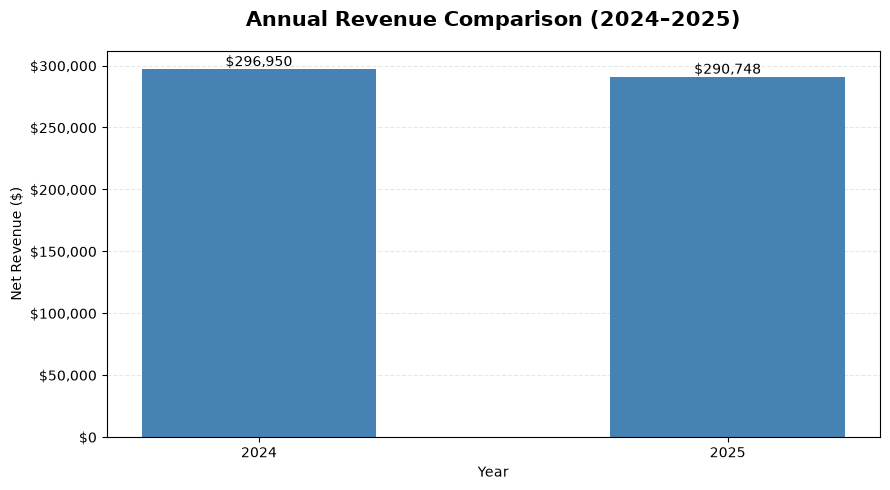

In [20]:

# ANNUAL REVENUE COMPARISON

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    annual_performance["order_year"].astype(str),
    annual_performance["total_revenue"],
    width=0.5,
    color="steelblue"
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Annual Revenue Comparison (2024–2025)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Net Revenue ($)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [21]:

# MONTHLY SALES PERFORMANCE

monthly_performance = (
    clean_df.groupby("order_month")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

# Convert month labels to datetime for chronological sorting

monthly_performance["month_date"] = pd.to_datetime(
    monthly_performance["order_month"],
    format="%Y-%m"
)

monthly_performance = monthly_performance.sort_values(
    "month_date"
).reset_index(drop=True)

# Display monthly performance

display(
    monthly_performance[
        ["order_month", "total_revenue", "total_orders", "units_sold"]
    ].style.format({
        "total_revenue": "${:,.2f}"
    })
)


,order_month,total_revenue,total_orders,units_sold
0,2024-01,"$21,228.20",62,132
1,2024-02,"$21,000.15",60,124
2,2024-03,"$28,764.85",68,135
3,2024-04,"$18,690.60",56,117
4,2024-05,"$25,289.55",68,146
5,2024-06,"$21,226.40",63,112
6,2024-07,"$41,454.35",63,127
7,2024-08,"$23,684.40",66,125
8,2024-09,"$24,024.40",50,103
9,2024-10,"$21,145.10",68,132


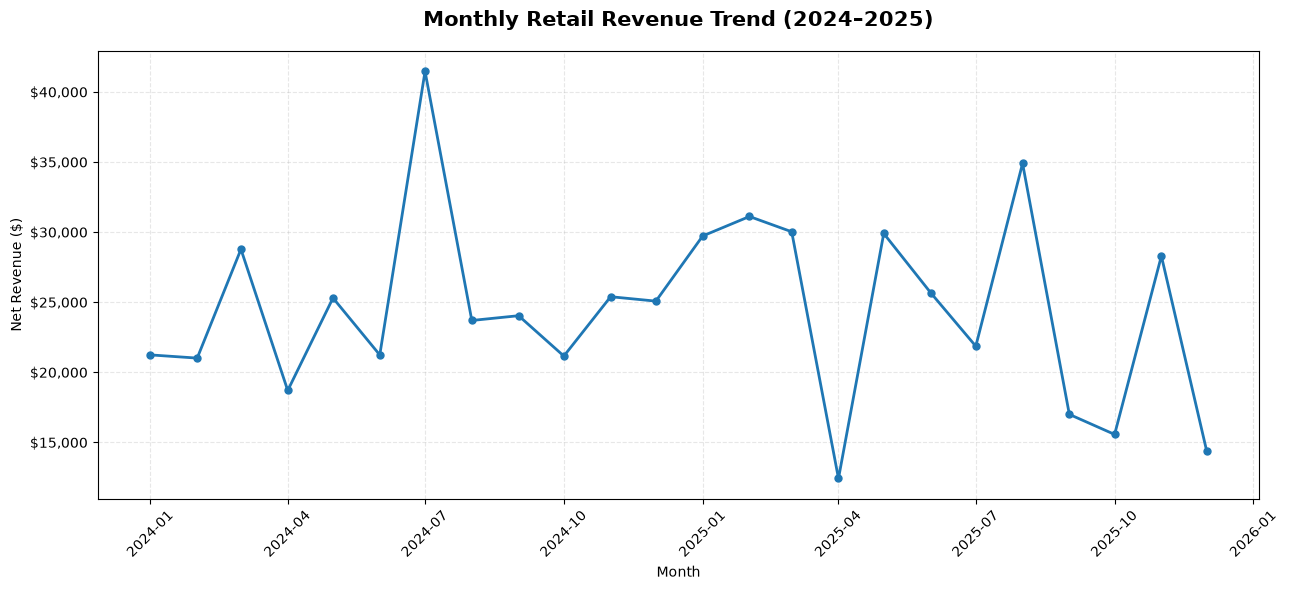

In [22]:

# MONTHLY REVENUE TREND

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_performance["month_date"],
    monthly_performance["total_revenue"],
    marker="o",
    linewidth=2,
    markersize=5
)

ax.set_title(
    "Monthly Retail Revenue Trend (2024–2025)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Net Revenue ($)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.tick_params(axis="x", rotation=45)

ax.grid(
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [23]:

# QUARTERLY SALES PERFORMANCE

quarterly_performance = (
    clean_df.groupby("order_quarter")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
    .sort_values("order_quarter")
    .reset_index(drop=True)
)

quarterly_performance["revenue_contribution_pct"] = (
    quarterly_performance["total_revenue"]
    / total_revenue * 100
)

display(
    quarterly_performance.style.format({
        "total_revenue": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)

# Identify the strongest quarter

top_quarter = quarterly_performance.loc[
    quarterly_performance["total_revenue"].idxmax()
]

print("\nHIGHEST-REVENUE QUARTER")
print("=" * 40)

print(f"Quarter: {top_quarter['order_quarter']}")
print(f"Revenue: ${top_quarter['total_revenue']:,.2f}")
print(
    f"Revenue contribution: "
    f"{top_quarter['revenue_contribution_pct']:.2f}%"
)


,order_quarter,total_revenue,total_orders,units_sold,revenue_contribution_pct
0,2024Q1,"$70,993.20",190,391,12.08%
1,2024Q2,"$65,206.55",187,375,11.10%
2,2024Q3,"$89,163.15",179,355,15.17%
3,2024Q4,"$71,587.05",180,385,12.18%
4,2025Q1,"$90,824.10",213,420,15.45%
5,2025Q2,"$67,978.00",171,331,11.57%
6,2025Q3,"$73,722.50",198,385,12.54%
7,2025Q4,"$58,223.00",182,356,9.91%



HIGHEST-REVENUE QUARTER
Quarter: 2025Q1
Revenue: $90,824.10
Revenue contribution: 15.45%


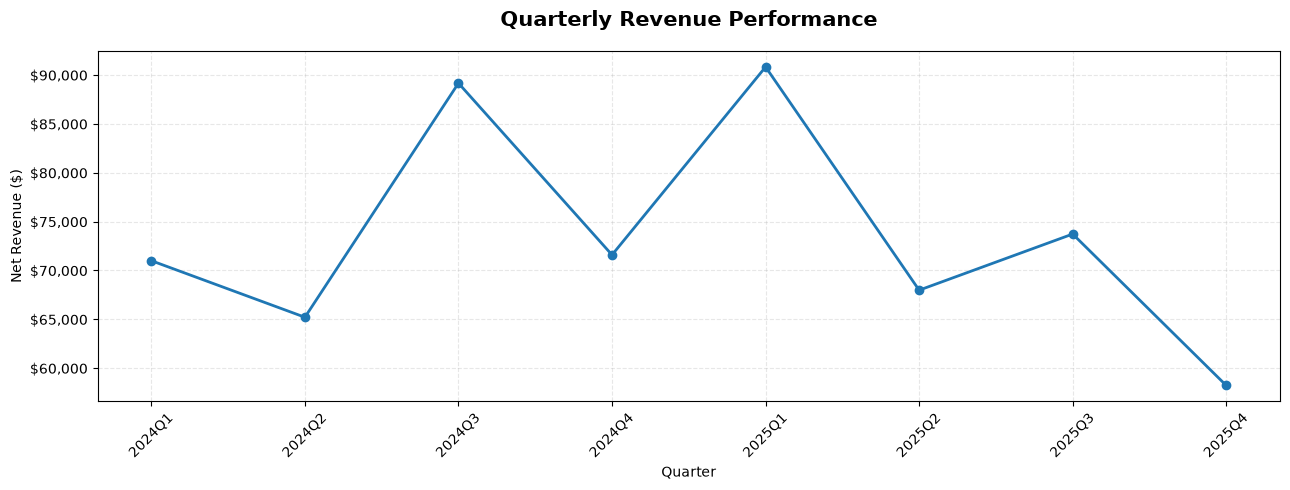

In [24]:

# QUARTERLY REVENUE VISUALIZATION

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    quarterly_performance["order_quarter"],
    quarterly_performance["total_revenue"],
    marker="o",
    linewidth=2,
    markersize=6
)

ax.set_title(
    "Quarterly Revenue Performance",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Quarter")
ax.set_ylabel("Net Revenue ($)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.tick_params(axis="x", rotation=45)
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



## 13. Customer Purchasing Behavior Analysis

This section examines customer purchasing patterns and their contribution to overall retail sales performance.

The analysis focuses on:

- Unique customer identification.
- Purchase frequency.
- Repeat customer activity.
- Customer lifetime revenue within the observed dataset.
- Average customer spending.
- Revenue concentration among high-value customers.

The objective is to understand customer purchasing behavior and identify the customers contributing most significantly to business revenue.

**Analytical note:** Customer identifiers are synthetically generated. The resulting analysis demonstrates customer-level aggregation techniques rather than actual customer behavior.


In [25]:

# CUSTOMER PURCHASING BEHAVIOR ANALYSIS

customer_performance = (
    clean_df.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("net_revenue", "sum"),
        total_units=("quantity", "sum"),
        average_order_value=("net_revenue", "mean"),
        first_purchase=("order_date", "min"),
        last_purchase=("order_date", "max")
    )
    .reset_index()
)

# Rank customers by revenue

customer_performance = (
    customer_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Calculate customer-level revenue contribution

customer_performance["revenue_contribution_pct"] = (
    customer_performance["total_revenue"]
    / total_revenue * 100
)

# Display the top 10 customers

print("TOP 10 CUSTOMERS BY REVENUE")
print("=" * 60)

display(
    customer_performance.head(10).style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


TOP 10 CUSTOMERS BY REVENUE


,customer_id,total_orders,total_revenue,total_units,average_order_value,first_purchase,last_purchase,revenue_contribution_pct
0,C0073,8,"$8,564.30",21,"$1,070.54",2024-01-08 00:00:00,2025-08-25 00:00:00,1.46%
1,C0118,11,"$7,738.95",22,$703.54,2024-01-13 00:00:00,2025-11-21 00:00:00,1.32%
2,C0120,8,"$7,460.35",17,$932.54,2024-03-05 00:00:00,2025-06-29 00:00:00,1.27%
3,C0006,3,"$7,419.00",9,"$2,473.00",2024-09-16 00:00:00,2025-03-05 00:00:00,1.26%
4,C0005,7,"$6,981.00",18,$997.29,2024-03-11 00:00:00,2025-12-03 00:00:00,1.19%
5,C0183,6,"$6,872.40",13,"$1,145.40",2024-08-12 00:00:00,2025-06-07 00:00:00,1.17%
6,C0269,6,"$6,482.75",11,"$1,080.46",2024-06-02 00:00:00,2025-09-13 00:00:00,1.10%
7,C0191,6,"$6,209.00",10,"$1,034.83",2024-05-09 00:00:00,2025-06-13 00:00:00,1.06%
8,C0069,7,"$5,800.60",13,$828.66,2024-05-24 00:00:00,2025-11-04 00:00:00,0.99%
9,C0167,8,"$5,596.70",15,$699.59,2024-01-09 00:00:00,2025-06-24 00:00:00,0.95%


In [26]:

# CUSTOMER PURCHASING BEHAVIOR ANALYSIS

customer_performance = (
    clean_df.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("net_revenue", "sum"),
        total_units=("quantity", "sum"),
        average_order_value=("net_revenue", "mean"),
        first_purchase=("order_date", "min"),
        last_purchase=("order_date", "max")
    )
    .reset_index()
)

# Rank customers by revenue

customer_performance = (
    customer_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Calculate customer-level revenue contribution

customer_performance["revenue_contribution_pct"] = (
    customer_performance["total_revenue"]
    / total_revenue * 100
)

# Display the top 10 customers

print("TOP 10 CUSTOMERS BY REVENUE")
print("=" * 60)

display(
    customer_performance.head(10).style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


TOP 10 CUSTOMERS BY REVENUE


,customer_id,total_orders,total_revenue,total_units,average_order_value,first_purchase,last_purchase,revenue_contribution_pct
0,C0073,8,"$8,564.30",21,"$1,070.54",2024-01-08 00:00:00,2025-08-25 00:00:00,1.46%
1,C0118,11,"$7,738.95",22,$703.54,2024-01-13 00:00:00,2025-11-21 00:00:00,1.32%
2,C0120,8,"$7,460.35",17,$932.54,2024-03-05 00:00:00,2025-06-29 00:00:00,1.27%
3,C0006,3,"$7,419.00",9,"$2,473.00",2024-09-16 00:00:00,2025-03-05 00:00:00,1.26%
4,C0005,7,"$6,981.00",18,$997.29,2024-03-11 00:00:00,2025-12-03 00:00:00,1.19%
5,C0183,6,"$6,872.40",13,"$1,145.40",2024-08-12 00:00:00,2025-06-07 00:00:00,1.17%
6,C0269,6,"$6,482.75",11,"$1,080.46",2024-06-02 00:00:00,2025-09-13 00:00:00,1.10%
7,C0191,6,"$6,209.00",10,"$1,034.83",2024-05-09 00:00:00,2025-06-13 00:00:00,1.06%
8,C0069,7,"$5,800.60",13,$828.66,2024-05-24 00:00:00,2025-11-04 00:00:00,0.99%
9,C0167,8,"$5,596.70",15,$699.59,2024-01-09 00:00:00,2025-06-24 00:00:00,0.95%


In [27]:

# CUSTOMER BEHAVIOR KPIs

total_unique_customers = customer_performance["customer_id"].nunique()

repeat_customers = (
    customer_performance["total_orders"] > 1
).sum()

one_time_customers = (
    customer_performance["total_orders"] == 1
).sum()

repeat_customer_rate = (
    repeat_customers / total_unique_customers * 100
)

average_orders_per_customer = (
    customer_performance["total_orders"].mean()
)

average_customer_revenue = (
    customer_performance["total_revenue"].mean()
)

# Revenue contribution of the top 10 customers

top_10_revenue = (
    customer_performance.head(10)["total_revenue"].sum()
)

top_10_revenue_share = (
    top_10_revenue / total_revenue * 100
)

# Display customer metrics

customer_kpis = pd.DataFrame({
    "Metric": [
        "Unique Customers",
        "Repeat Customers",
        "One-Time Customers",
        "Repeat Customer Rate",
        "Average Orders per Customer",
        "Average Customer Revenue",
        "Top 10 Customer Revenue Share"
    ],

    "Value": [
        f"{total_unique_customers:,}",
        f"{repeat_customers:,}",
        f"{one_time_customers:,}",
        f"{repeat_customer_rate:.2f}%",
        f"{average_orders_per_customer:.2f}",
        f"${average_customer_revenue:,.2f}",
        f"{top_10_revenue_share:.2f}%"
    ]
})

display(customer_kpis)


,Metric,Value
0,Unique Customers,298
1,Repeat Customers,289
2,One-Time Customers,9
3,Repeat Customer Rate,96.98%
4,Average Orders per Customer,5.03
5,Average Customer Revenue,"$1,972.14"
6,Top 10 Customer Revenue Share,11.76%


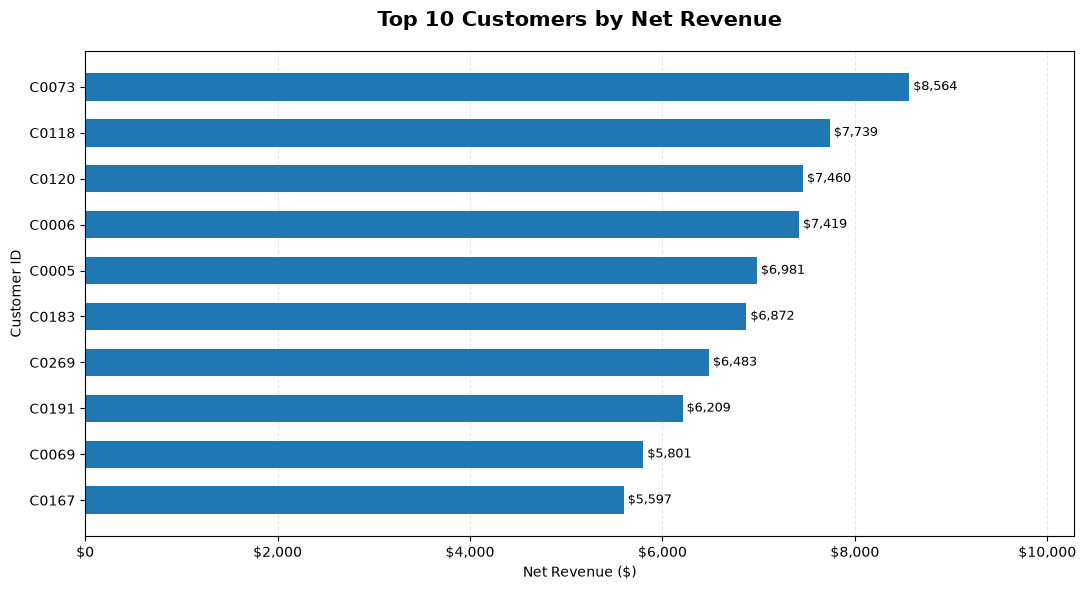

In [28]:

# TOP 10 CUSTOMERS BY REVENUE

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

top_customers = (
    customer_performance
    .head(10)
    .sort_values("total_revenue", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_customers["customer_id"],
    top_customers["total_revenue"],
    height=0.6
)

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" ${width:,.0f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 10 Customers by Net Revenue",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Net Revenue ($)")
ax.set_ylabel("Customer ID")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.set_xlim(
    0,
    top_customers["total_revenue"].max() * 1.2
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


,number_of_orders,number_of_customers
0,1,9
1,2,20
2,3,46
3,4,58
4,5,48
5,6,47
6,7,30
7,8,26
8,9,5
9,10,5


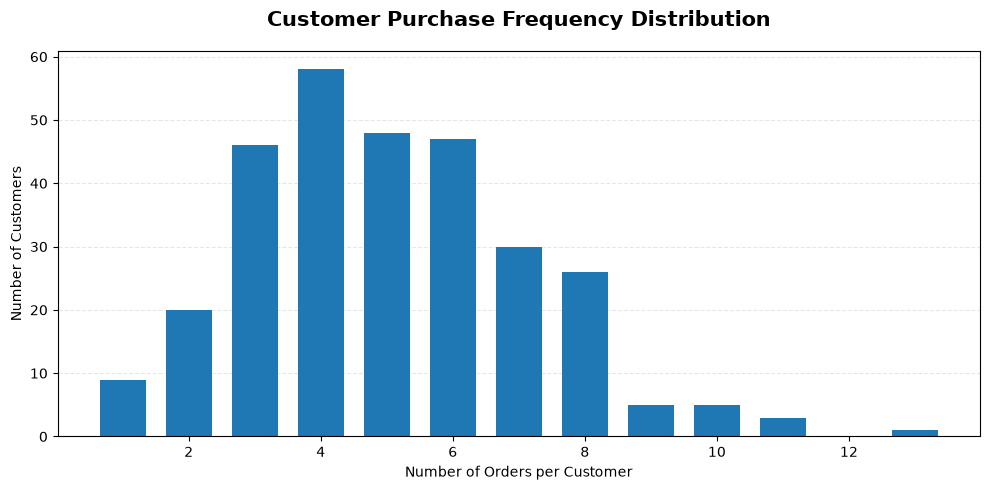

In [29]:

# CUSTOMER PURCHASE FREQUENCY DISTRIBUTION

frequency_distribution = (
    customer_performance["total_orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_distribution.columns = [
    "number_of_orders",
    "number_of_customers"
]

display(frequency_distribution)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    frequency_distribution["number_of_orders"],
    frequency_distribution["number_of_customers"],
    width=0.7
)

ax.set_title(
    "Customer Purchase Frequency Distribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Number of Orders per Customer")
ax.set_ylabel("Number of Customers")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



## 14. Sales Channel and Payment Method Analysis

This section evaluates retail performance across different sales channels and payment methods.

The analysis focuses on:

- Revenue generated by each sales channel.
- Transaction volume by sales channel.
- Average order value across channels.
- Revenue contribution by channel.
- Payment method distribution.
- Revenue generated through different payment methods.

The objective is to understand how transactions are distributed across sales channels and payment methods.

**Data note:** Sales channels and payment methods are synthetically assigned for demonstration purposes.


In [30]:

# SALES CHANNEL PERFORMANCE ANALYSIS

sales_channel_performance = (
    clean_df.groupby("sales_channel")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        unique_customers=("customer_id", "nunique"),
        total_discounts=("discount_amount", "sum")
    )
    .reset_index()
)

# Calculate average order value

sales_channel_performance["average_order_value"] = (
    sales_channel_performance["total_revenue"]
    / sales_channel_performance["total_orders"]
)

# Calculate revenue contribution

sales_channel_performance["revenue_contribution_pct"] = (
    sales_channel_performance["total_revenue"]
    / total_revenue * 100
)

# Rank channels by revenue

sales_channel_performance = (
    sales_channel_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Display the results

display(
    sales_channel_performance.style.format({
        "total_revenue": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "total_discounts": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


,sales_channel,total_revenue,total_orders,units_sold,unique_customers,total_discounts,average_order_value,revenue_contribution_pct
0,Online,"$293,642.25",755,1502,277,"$15,524.75",$388.93,49.96%
1,Physical Store,"$211,921.20",529,1056,258,"$11,202.80",$400.61,36.06%
2,Partner,"$82,134.10",216,440,151,"$3,940.90",$380.25,13.98%


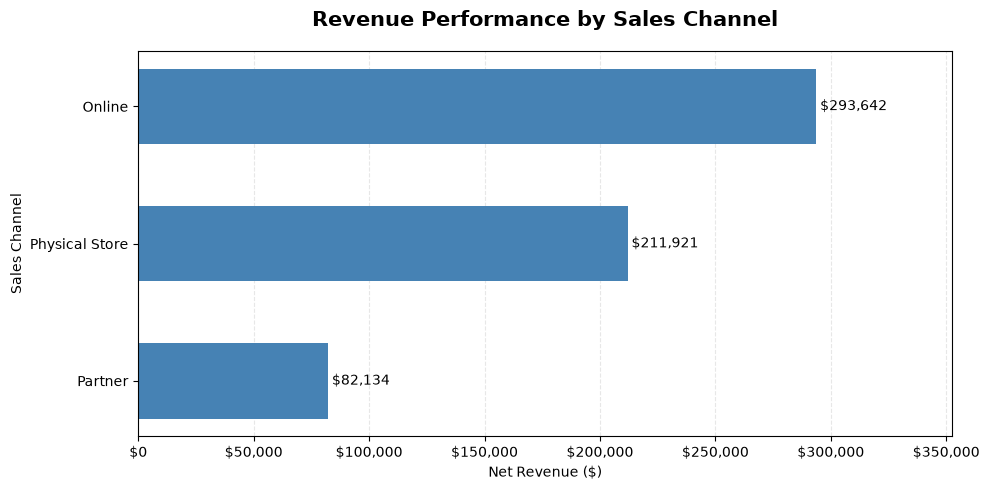

In [31]:

# SALES CHANNEL REVENUE COMPARISON

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plot_data = sales_channel_performance.sort_values(
    "total_revenue",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data["sales_channel"],
    plot_data["total_revenue"],
    height=0.55,
    color="steelblue"
)

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" ${width:,.0f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Revenue Performance by Sales Channel",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Net Revenue ($)")
ax.set_ylabel("Sales Channel")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.set_xlim(0, plot_data["total_revenue"].max() * 1.2)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


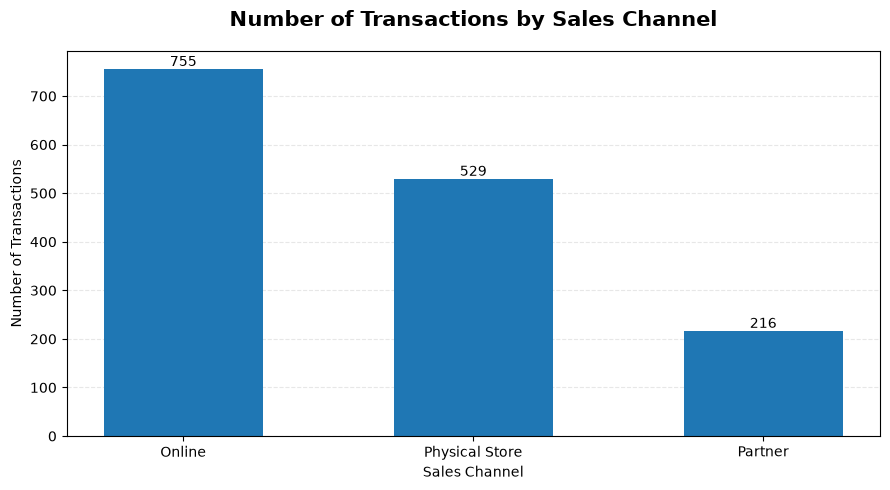

In [32]:

# TRANSACTION VOLUME BY SALES CHANNEL

channel_orders = (
    sales_channel_performance
    .sort_values("total_orders", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    channel_orders["sales_channel"],
    channel_orders["total_orders"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Number of Transactions by Sales Channel",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Sales Channel")
ax.set_ylabel("Number of Transactions")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [33]:

# PAYMENT METHOD PERFORMANCE ANALYSIS

payment_performance = (
    clean_df.groupby("payment_method")
    .agg(
        total_revenue=("net_revenue", "sum"),
        total_transactions=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

# Calculate payment method transaction share

payment_performance["transaction_share_pct"] = (
    payment_performance["total_transactions"]
    / total_orders * 100
)

# Calculate revenue contribution

payment_performance["revenue_contribution_pct"] = (
    payment_performance["total_revenue"]
    / total_revenue * 100
)

# Rank by transaction volume

payment_performance = (
    payment_performance
    .sort_values("total_transactions", ascending=False)
    .reset_index(drop=True)
)

display(
    payment_performance.style.format({
        "total_revenue": "${:,.2f}",
        "transaction_share_pct": "{:.2f}%",
        "revenue_contribution_pct": "{:.2f}%"
    })
)


,payment_method,total_revenue,total_transactions,units_sold,transaction_share_pct,revenue_contribution_pct
0,Credit Card,"$236,915.95",594,1177,39.60%,40.31%
1,Debit Card,"$167,287.60",452,909,30.13%,28.46%
2,Cash,"$101,135.90",234,500,15.60%,17.21%
3,PayPal,"$82,358.10",220,412,14.67%,14.01%


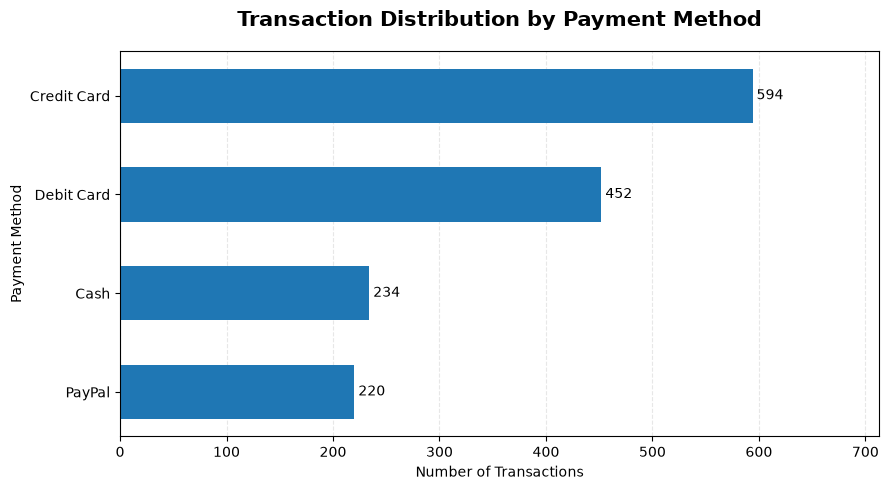

In [34]:

# PAYMENT METHOD TRANSACTION DISTRIBUTION

fig, ax = plt.subplots(figsize=(9, 5))

plot_data = payment_performance.sort_values(
    "total_transactions",
    ascending=True
)

bars = ax.barh(
    plot_data["payment_method"],
    plot_data["total_transactions"],
    height=0.55
)

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.0f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Transaction Distribution by Payment Method",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Number of Transactions")
ax.set_ylabel("Payment Method")

ax.set_xlim(0, plot_data["total_transactions"].max() * 1.2)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [35]:

# SALES CHANNEL AND PAYMENT METHOD SUMMARY

top_sales_channel = (
    sales_channel_performance.iloc[0]
)

top_payment_method = (
    payment_performance.iloc[0]
)

print("=" * 55)
print("SALES CHANNEL AND PAYMENT METHOD SUMMARY")
print("=" * 55)

print("\nTOP SALES CHANNEL")
print("-" * 35)

print(f"Channel: {top_sales_channel['sales_channel']}")

print(
    f"Revenue: "
    f"${top_sales_channel['total_revenue']:,.2f}"
)

print(
    f"Revenue Contribution: "
    f"{top_sales_channel['revenue_contribution_pct']:.2f}%"
)

print("\nMOST FREQUENT PAYMENT METHOD")
print("-" * 35)

print(f"Payment Method: {top_payment_method['payment_method']}")

print(
    f"Transactions: "
    f"{top_payment_method['total_transactions']:,}"
)

print(
    f"Transaction Share: "
    f"{top_payment_method['transaction_share_pct']:.2f}%"
)

print("\nAnalysis completed successfully.")


SALES CHANNEL AND PAYMENT METHOD SUMMARY

TOP SALES CHANNEL
-----------------------------------
Channel: Online
Revenue: $293,642.25
Revenue Contribution: 49.96%

MOST FREQUENT PAYMENT METHOD
-----------------------------------
Payment Method: Credit Card
Transactions: 594
Transaction Share: 39.60%

Analysis completed successfully.



## 15. Product-Level Performance and Discount Analysis

This section investigates individual product performance and evaluates the distribution of discounts across retail transactions.

The analysis focuses on:

- Revenue generated by individual products.
- Number of transactions per product.
- Total units sold.
- Average transaction value.
- Product revenue contribution.
- Discount distribution across transactions.
- Comparison of gross and net revenue at different discount levels.

The objective is to identify high-performing products and understand the relationship between discount levels and observed sales performance.

**Analytical limitation:** The dataset uses randomly assigned discount rates. Consequently, the analysis is descriptive and cannot establish whether discounts cause an increase in sales.


In [36]:

# PRODUCT-LEVEL PERFORMANCE ANALYSIS

product_performance = (
    clean_df.groupby(
        ["product_id", "product_name", "category"]
    )
    .agg(
        total_revenue=("net_revenue", "sum"),
        gross_revenue=("gross_revenue", "sum"),
        total_discounts=("discount_amount", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        average_order_value=("net_revenue", "mean"),
        average_discount_pct=("discount_pct", "mean")
    )
    .reset_index()
)

# Calculate revenue contribution

product_performance["revenue_contribution_pct"] = (
    product_performance["total_revenue"]
    / clean_df["net_revenue"].sum() * 100
)

# Calculate average net selling price per unit

product_performance["average_net_unit_price"] = (
    product_performance["total_revenue"]
    / product_performance["units_sold"]
)

# Rank products by revenue

product_performance = (
    product_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

# Display product performance

display(
    product_performance.style.format({
        "total_revenue": "${:,.2f}",
        "gross_revenue": "${:,.2f}",
        "total_discounts": "${:,.2f}",
        "average_order_value": "${:,.2f}",
        "average_discount_pct": "{:.2%}",
        "revenue_contribution_pct": "{:.2f}%",
        "average_net_unit_price": "${:,.2f}"
    })
)


,product_id,product_name,category,total_revenue,gross_revenue,total_discounts,total_orders,units_sold,average_order_value,average_discount_pct,revenue_contribution_pct,average_net_unit_price
0,P002,Laptop,Electronics,"$218,757.55","$230,208.00","$11,450.45",101,192,"$2,165.92",4.85%,37.22%,"$1,139.36"
1,P001,Smartphone,Electronics,"$126,484.05","$132,810.00","$6,325.95",92,190,"$1,374.83",5.00%,21.52%,$665.71
2,P008,Vacuum Cleaner,Home & Kitchen,"$41,094.05","$43,510.00","$2,415.95",106,190,$387.68,6.13%,6.99%,$216.28
3,P004,Monitor,Electronics,"$40,985.10","$42,687.00","$1,701.90",76,153,$539.28,4.67%,6.97%,$267.88
4,P003,Headphones,Electronics,"$26,171.85","$27,416.00","$1,244.15",98,184,$267.06,4.90%,4.45%,$142.24
5,P007,Air Fryer,Home & Kitchen,"$22,458.90","$23,349.00",$890.10,88,181,$255.21,3.64%,3.82%,$124.08
6,P011,Jacket,Clothing,"$19,596.50","$20,900.00","$1,303.50",98,190,$199.96,5.97%,3.33%,$103.14
7,P014,Running Shoes,Sports & Outdoors,"$19,280.25","$20,615.00","$1,334.75",95,217,$202.95,6.32%,3.28%,$88.85
8,P005,Coffee Maker,Home & Kitchen,"$15,454.85","$16,287.00",$832.15,92,183,$167.99,5.65%,2.63%,$84.45
9,P013,Dumbbell Set,Sports & Outdoors,"$15,041.25","$15,825.00",$783.75,105,211,$143.25,4.90%,2.56%,$71.29


In [39]:

# TOP 10 PRODUCTS BY NET REVENUE

top_products = product_performance.head(10).copy()

display(
    top_products[
        [
            "product_name",
            "category",
            "total_revenue",
            "units_sold",
            "total_orders",
            "revenue_contribution_pct"
        ]
    ].style.format({
        "total_revenue": "${:,.2f}",
        "revenue_contribution_pct": "{:.2f}%"
    })
)

# Identify the leading product

best_product = product_performance.iloc[0]

print("\nTOP  REVENUE-GENERATING PRODUCT")
print("=" * 45)

print(f"Product: {best_product['product_name']}")
print(f"Category: {best_product['category']}")

print(
    f"Net Revenue: "
    f"${best_product['total_revenue']:,.2f}"
)

print(f"Units Sold: {best_product['units_sold']:,}")

print(
    f"Revenue Contribution: "
    f"{best_product['revenue_contribution_pct']:.2f}%"
)


,product_name,category,total_revenue,units_sold,total_orders,revenue_contribution_pct
0,Laptop,Electronics,"$218,757.55",192,101,37.22%
1,Smartphone,Electronics,"$126,484.05",190,92,21.52%
2,Vacuum Cleaner,Home & Kitchen,"$41,094.05",190,106,6.99%
3,Monitor,Electronics,"$40,985.10",153,76,6.97%
4,Headphones,Electronics,"$26,171.85",184,98,4.45%
5,Air Fryer,Home & Kitchen,"$22,458.90",181,88,3.82%
6,Jacket,Clothing,"$19,596.50",190,98,3.33%
7,Running Shoes,Sports & Outdoors,"$19,280.25",217,95,3.28%
8,Coffee Maker,Home & Kitchen,"$15,454.85",183,92,2.63%
9,Dumbbell Set,Sports & Outdoors,"$15,041.25",211,105,2.56%



TOP  REVENUE-GENERATING PRODUCT
Product: Laptop
Category: Electronics
Net Revenue: $218,757.55
Units Sold: 192
Revenue Contribution: 37.22%


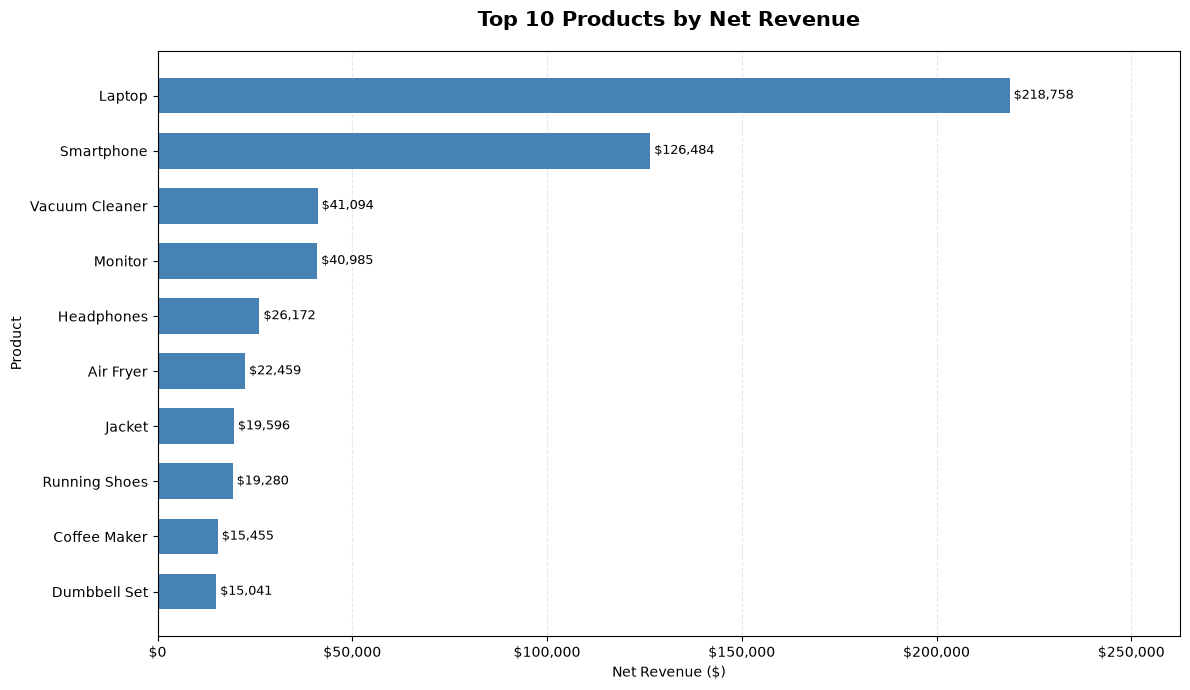

In [40]:

# TOP 10 PRODUCTS REVENUE VISUALIZATION

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plot_data = (
    top_products
    .sort_values("total_revenue", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    plot_data["product_name"],
    plot_data["total_revenue"],
    height=0.65,
    color="steelblue"
)

for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" ${width:,.0f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 10 Products by Net Revenue",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Net Revenue ($)")
ax.set_ylabel("Product")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}")
)

ax.set_xlim(
    0,
    plot_data["total_revenue"].max() * 1.2
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [41]:

# DISCOUNT PERFORMANCE ANALYSIS

discount_performance = (
    clean_df.groupby("discount_pct")
    .agg(
        total_transactions=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        gross_revenue=("gross_revenue", "sum"),
        total_discounts=("discount_amount", "sum"),
        net_revenue=("net_revenue", "sum"),
        average_gross_order_value=("gross_revenue", "mean"),
        average_net_order_value=("net_revenue", "mean")
    )
    .reset_index()
    .sort_values("discount_pct")
)

# Create readable discount labels

discount_performance["discount_level"] = (
    discount_performance["discount_pct"]
    .map(lambda value: f"{value:.0%}")
)

# Calculate transaction and revenue contributions

discount_performance["transaction_share_pct"] = (
    discount_performance["total_transactions"]
    / clean_df["order_id"].nunique() * 100
)

discount_performance["revenue_contribution_pct"] = (
    discount_performance["net_revenue"]
    / clean_df["net_revenue"].sum() * 100
)

# Display discount analysis

display(
    discount_performance[
        [
            "discount_level",
            "total_transactions",
            "units_sold",
            "gross_revenue",
            "total_discounts",
            "net_revenue",
            "average_net_order_value",
            "transaction_share_pct"
        ]
    ].style.format({
        "gross_revenue": "${:,.2f}",
        "total_discounts": "${:,.2f}",
        "net_revenue": "${:,.2f}",
        "average_net_order_value": "${:,.2f}",
        "transaction_share_pct": "{:.2f}%"
    })
)


,discount_level,total_transactions,units_sold,gross_revenue,total_discounts,net_revenue,average_net_order_value,transaction_share_pct
0,0%,714,1424,"$307,014.00",$0.00,"$307,014.00",$429.99,47.60%
1,5%,286,586,"$111,782.00","$5,589.10","$106,192.90",$371.30,19.07%
2,10%,274,551,"$120,272.00","$12,027.20","$108,244.80",$395.05,18.27%
3,15%,165,324,"$56,149.00","$8,422.35","$47,726.65",$289.25,11.00%
4,20%,61,113,"$23,149.00","$4,629.80","$18,519.20",$303.59,4.07%


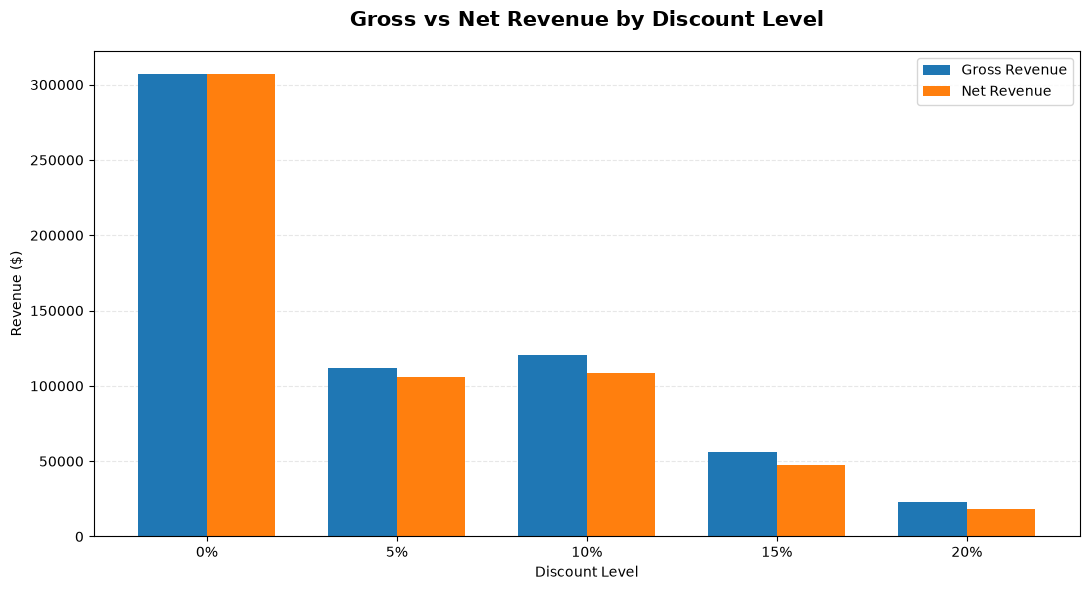

In [42]:

# GROSS VS NET REVENUE BY DISCOUNT LEVEL

import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(discount_performance))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    discount_performance["gross_revenue"],
    width,
    label="Gross Revenue"
)

ax.bar(
    x + width / 2,
    discount_performance["net_revenue"],
    width,
    label="Net Revenue"
)

ax.set_title(
    "Gross vs Net Revenue by Discount Level",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Discount Level")
ax.set_ylabel("Revenue ($)")

ax.set_xticks(x)
ax.set_xticklabels(
    discount_performance["discount_level"]
)

ax.legend()

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



## 16. Correlation Analysis

This section investigates statistical relationships between numerical variables in the retail sales dataset.

The analysis examines relationships between:

- Unit price
- Quantity purchased
- Discount percentage
- Gross revenue
- Discount amount
- Net revenue

Pearson and Spearman correlation coefficients are used to identify linear and monotonic relationships.

The objective is to understand how numerical transaction characteristics relate to observed revenue performance.

**Analytical limitation:** Correlation does not imply causation. Furthermore, revenue variables are mathematically derived from prices, quantities, and discounts, meaning some observed correlations are structural rather than independent business relationships.


In [43]:

# PEARSON CORRELATION ANALYSIS

correlation_columns = [
    "unit_price",
    "quantity",
    "discount_pct",
    "gross_revenue",
    "discount_amount",
    "net_revenue"
]

correlation_data = clean_df[correlation_columns]

pearson_correlation = correlation_data.corr(
    method="pearson"
)

print("PEARSON CORRELATION MATRIX")
print("=" * 50)

display(
    pearson_correlation.style.format("{:.3f}")
)


PEARSON CORRELATION MATRIX


,unit_price,quantity,discount_pct,gross_revenue,discount_amount,net_revenue
unit_price,1.000,-0.021,-0.021,0.843,0.473,0.843
quantity,-0.021,1.000,-0.016,0.285,0.178,0.283
discount_pct,-0.021,-0.016,1.000,-0.027,0.369,-0.063
gross_revenue,0.843,0.285,-0.027,1.000,0.600,0.997
discount_amount,0.473,0.178,0.369,0.600,1.000,0.539
net_revenue,0.843,0.283,-0.063,0.997,0.539,1.000


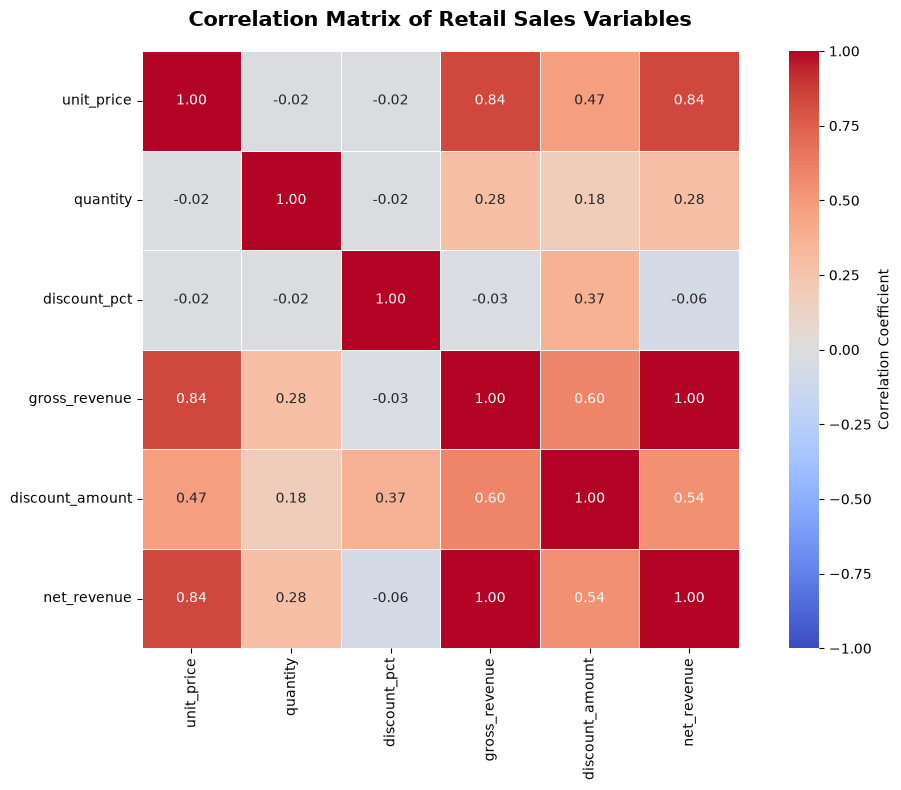

In [44]:

# CORRELATION HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    pearson_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlation Coefficient"},
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Retail Sales Variables",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.tight_layout()
plt.show()


In [45]:

# SPEARMAN CORRELATION ANALYSIS

spearman_correlation = correlation_data.corr(
    method="spearman"
)

print("SPEARMAN CORRELATION MATRIX")
print("=" * 50)

display(
    spearman_correlation.style.format("{:.3f}")
)


SPEARMAN CORRELATION MATRIX


,unit_price,quantity,discount_pct,gross_revenue,discount_amount,net_revenue
unit_price,1.000,-0.021,-0.016,0.863,0.212,0.862
quantity,-0.021,1.000,-0.024,0.444,0.093,0.444
discount_pct,-0.016,-0.024,1.000,-0.020,0.901,-0.078
gross_revenue,0.863,0.444,-0.020,1.000,0.248,0.998
discount_amount,0.212,0.093,0.901,0.248,1.000,0.198
net_revenue,0.862,0.444,-0.078,0.998,0.198,1.000


In [46]:

# CORRELATION WITH NET REVENUE

pearson_revenue_corr = (
    pearson_correlation["net_revenue"]
    .drop("net_revenue")
)

spearman_revenue_corr = (
    spearman_correlation["net_revenue"]
    .drop("net_revenue")
)

revenue_correlations = pd.DataFrame({
    "Variable": pearson_revenue_corr.index,
    "Pearson Correlation": pearson_revenue_corr.values,
    "Spearman Correlation": spearman_revenue_corr.values
})

revenue_correlations["Absolute Pearson Correlation"] = (
    revenue_correlations["Pearson Correlation"].abs()
)

revenue_correlations = (
    revenue_correlations
    .sort_values(
        "Absolute Pearson Correlation",
        ascending=False
    )
    .drop(columns="Absolute Pearson Correlation")
    .reset_index(drop=True)
)

display(
    revenue_correlations.style.format({
        "Pearson Correlation": "{:.3f}",
        "Spearman Correlation": "{:.3f}"
    })
)


,Variable,Pearson Correlation,Spearman Correlation
0,gross_revenue,0.997,0.998
1,unit_price,0.843,0.862
2,discount_amount,0.539,0.198
3,quantity,0.283,0.444
4,discount_pct,-0.063,-0.078


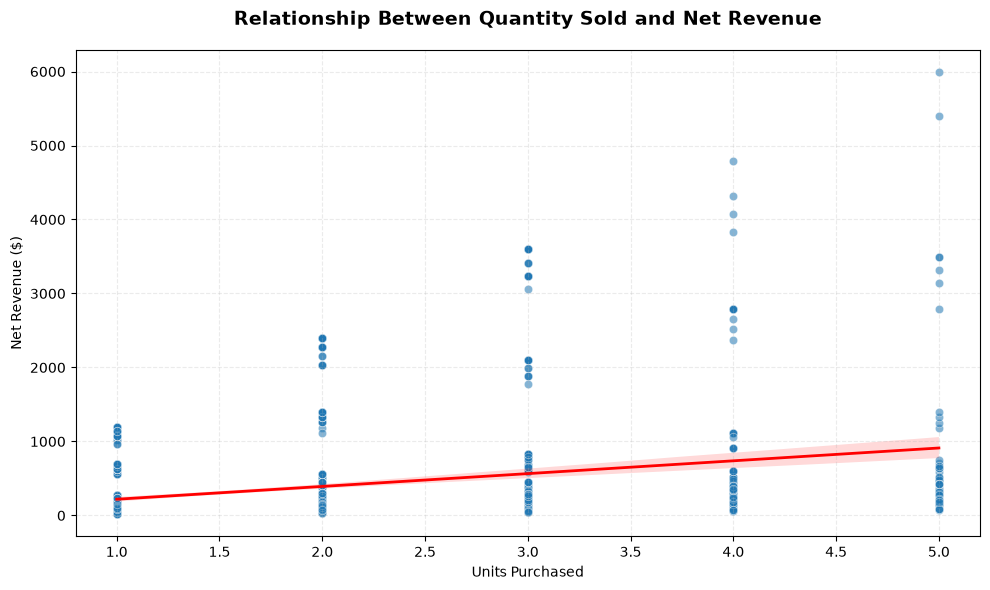

In [47]:

# QUANTITY VS NET REVENUE

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=clean_df,
    x="quantity",
    y="net_revenue",
    alpha=0.55,
    ax=ax
)

sns.regplot(
    data=clean_df,
    x="quantity",
    y="net_revenue",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2},
    ax=ax
)

ax.set_title(
    "Relationship Between Quantity Sold and Net Revenue",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Units Purchased")
ax.set_ylabel("Net Revenue ($)")

ax.grid(linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()


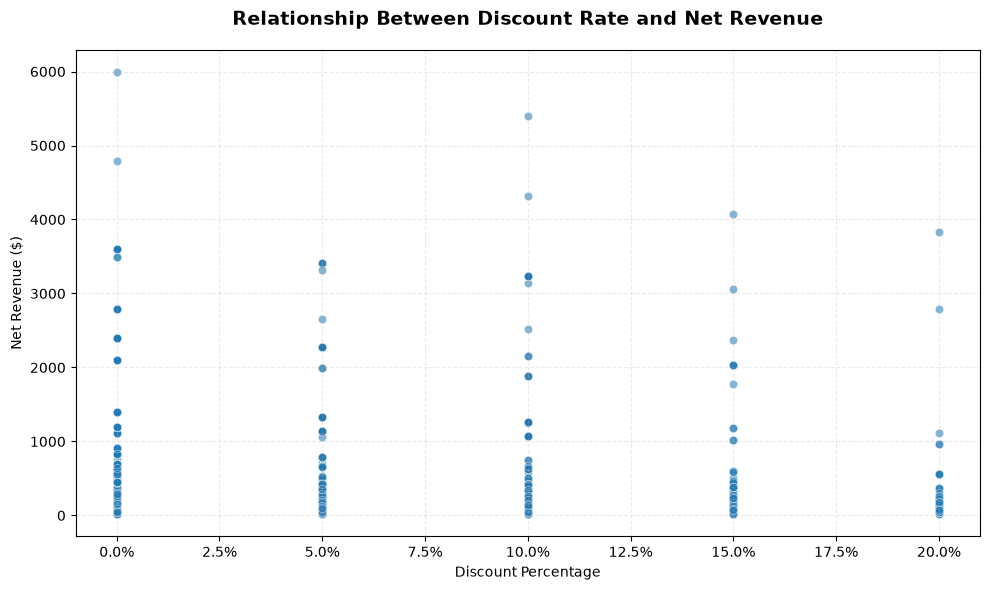

In [48]:

# DISCOUNT PERCENTAGE VS NET REVENUE

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=clean_df,
    x="discount_pct",
    y="net_revenue",
    alpha=0.55,
    ax=ax
)

ax.set_title(
    "Relationship Between Discount Rate and Net Revenue",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Discount Percentage")
ax.set_ylabel("Net Revenue ($)")

from matplotlib.ticker import PercentFormatter

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.grid(linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()


---

# </p>

# 17. Executive Summary and Business Insights

## **Management Overview**

#### This section consolidates the findings from the retail sales performance analysis.

#### The objective is to transform the analytical results into a concise business report highlighting overall performance, </p>leading product categories, regional contributions, customer activity, and sales trends.

## **Key Performance Indicators**

#### A summary of the principal financial and operational metrics is presented below.

## **Key Analytical Findings**

#### This section identifies the strongest-performing product categories, products, regions, and sales channels.

## **Business Implications**

#### The results are used to identify areas that warrant further investigation, including product performance, market distribution, customer purchasing patterns, and discount strategies.

## **Limitations**

#### The analysis uses synthetic demonstration data. Its findings illustrate analytical techniques and should not be interpreted as evidence of actual retail business performance.


In [49]:

# EXECUTIVE SUMMARY GENERATOR

from pathlib import Path

# 1. Identify leading business performers

leading_category = category_performance.iloc[0]
leading_product = product_performance.iloc[0]
leading_region = regional_performance.iloc[0]
leading_channel = sales_channel_performance.iloc[0]
leading_payment = payment_performance.iloc[0]
leading_quarter = quarterly_performance.loc[
    quarterly_performance["total_revenue"].idxmax()
]

# 2. Calculate annual revenue growth

annual_sorted = annual_performance.sort_values("order_year")

if len(annual_sorted) >= 2:
    previous_year = annual_sorted.iloc[-2]
    latest_year = annual_sorted.iloc[-1]

    previous_revenue = previous_year["total_revenue"]
    latest_revenue = latest_year["total_revenue"]

    annual_growth = (
        (latest_revenue - previous_revenue)
        / previous_revenue * 100
        if previous_revenue != 0 else None
    )
else:
    annual_growth = None

# 3. Build executive summary text

summary_lines = [
    "# Retail Sales Performance Analysis",
    "",
    "## Executive Summary",
    "",
    "This report summarizes the results of an exploratory "
    "analysis of 1,500 synthetic retail transactions covering "
    "2024–2025.",
    "",
    "### Overall Business Performance",
    "",
    f"- Total net revenue: ${total_revenue:,.2f}",
    f"- Total transactions: {total_orders:,}",
    f"- Average order value: ${average_order_value:,.2f}",
    f"- Total units sold: {total_units_sold:,}",
    f"- Unique customers: {total_customers:,}",
    f"- Total discounts: ${total_discounts:,.2f}",
    "",
    "### Leading Performance Areas",
    "",
    f"- Leading product category: {leading_category['category']} "
    f"(${leading_category['total_revenue']:,.2f} revenue).",
    "",
    f"- Leading individual product: {leading_product['product_name']} "
    f"(${leading_product['total_revenue']:,.2f} revenue).",
    "",
    f"- Highest-revenue region: {leading_region['region']} "
    f"(${leading_region['total_revenue']:,.2f} revenue).",
    "",
    f"- Leading sales channel: {leading_channel['sales_channel']} "
    f"(${leading_channel['total_revenue']:,.2f} revenue).",
    "",
    f"- Most frequently used payment method: "
    f"{leading_payment['payment_method']} "
    f"({leading_payment['total_transactions']:,} transactions).",
    "",
    f"- Highest-revenue quarter: "
    f"{leading_quarter['order_quarter']} "
    f"(${leading_quarter['total_revenue']:,.2f} revenue).",
    "",
    "### Annual Performance",
    ""
]

if annual_growth is not None:
    summary_lines.append(
        f"- Revenue change from "
        f"{int(previous_year['order_year'])} to "
        f"{int(latest_year['order_year'])}: "
        f"{annual_growth:+.2f}%."
    )
else:
    summary_lines.append(
        "- Insufficient annual observations to calculate growth."
    )

summary_lines.extend([
    "",
    "### Areas for Further Business Investigation",
    "",
    "1. Evaluate the revenue contribution and profitability "
    "of the highest-performing product categories.",
    "",
    "2. Investigate regional differences in revenue, customer "
    "activity, and average order value.",
    "",
    "3. Examine the performance of online, physical-store, "
    "and partner sales channels.",
    "",
    "4. Evaluate discount strategies using controlled experiments "
    "or comparable transaction groups.",
    "",
    "5. Investigate customer retention using reliable longitudinal "
    "customer data.",
    "",
    "### Data and Methodological Limitations",
    "",
    "This project uses synthetic data generated for educational "
    "and analytical demonstration purposes.",
    "",
    "The reported findings are not representative of an actual "
    "retail business.",
    "",
    "Randomly assigned customer IDs, regions, sales channels, "
    "and discounts limit the interpretation of behavioral patterns.",
    "",
    "Revenue should not be confused with profit because product "
    "cost and operating expenses are not available.",
    "",
    "---",
    "",
    "Report generated using Python, Pandas, NumPy, and Jupyter.",
])

executive_summary = "\n".join(summary_lines)

# 4. Display the report inside the notebook

from IPython.display import Markdown, display

display(Markdown(executive_summary))

# 5. Locate the project directory

current_path = Path.cwd()

project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "data" / "raw" / "retail_sales.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root."
    )

# 6. Save the executive summary

report_directory = project_root / "reports"
report_directory.mkdir(parents=True, exist_ok=True)

report_path = report_directory / "executive_summary.md"

report_path.write_text(
    executive_summary,
    encoding="utf-8"
)

print("\nExecutive summary successfully generated.")
print(f"Report saved to: {report_path}")


# Retail Sales Performance Analysis

## Executive Summary

This report summarizes the results of an exploratory analysis of 1,500 synthetic retail transactions covering 2024–2025.

### Overall Business Performance

- Total net revenue: $587,697.55
- Total transactions: 1,500
- Average order value: $391.80
- Total units sold: 2,998
- Unique customers: 298
- Total discounts: $30,668.45

### Leading Performance Areas

- Leading product category: Electronics ($412,398.55 revenue).

- Leading individual product: Laptop ($218,757.55 revenue).

- Highest-revenue region: West ($169,704.35 revenue).

- Leading sales channel: Online ($293,642.25 revenue).

- Most frequently used payment method: Credit Card (594 transactions).

- Highest-revenue quarter: 2025Q1 ($90,824.10 revenue).

### Annual Performance

- Revenue change from 2024 to 2025: -2.09%.

### Areas for Further Business Investigation

1. Evaluate the revenue contribution and profitability of the highest-performing product categories.

2. Investigate regional differences in revenue, customer activity, and average order value.

3. Examine the performance of online, physical-store, and partner sales channels.

4. Evaluate discount strategies using controlled experiments or comparable transaction groups.

5. Investigate customer retention using reliable longitudinal customer data.

### Data and Methodological Limitations

This project uses synthetic data generated for educational and analytical demonstration purposes.

The reported findings are not representative of an actual retail business.

Randomly assigned customer IDs, regions, sales channels, and discounts limit the interpretation of behavioral patterns.

Revenue should not be confused with profit because product cost and operating expenses are not available.

---

Report generated using Python, Pandas, NumPy, and Jupyter.


Executive summary successfully generated.
Report saved to: d:\Users\NoteBook\Desktop\retail-sales-performance-analysis\reports\executive_summary.md



## 18. Exporting Analytical Visualizations

This section exports selected visualizations as high-resolution PNG files.

The exported charts provide a standalone visual summary of the analytical findings and can be reused in project documentation, business reports, and presentations.

All figures are exported at 300 DPI for improved presentation quality.


In [50]:

# EXPORT PROFESSIONAL ANALYTICAL CHARTS

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the project directory

current_path = Path.cwd()

project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "data" / "raw" / "retail_sales.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root could not be located.")

# Create figure output directory

figures_directory = project_root / "reports" / "figures"

figures_directory.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# 1. REUSABLE HORIZONTAL BAR CHART EXPORT FUNCTION
# --------------------------------------------------

def export_revenue_chart(
    dataframe,
    label_column,
    value_column,
    chart_title,
    x_label,
    filename
):
    """Create and export a high-resolution revenue chart."""

    plot_data = dataframe.sort_values(
        value_column,
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        plot_data[label_column].astype(str),
        plot_data[value_column],
        height=0.6,
        color="steelblue"
    )

    for bar in bars:
        width = bar.get_width()

        ax.text(
            width,
            bar.get_y() + bar.get_height() / 2,
            f" ${width:,.0f}",
            va="center",
            fontsize=9
        )

    ax.set_title(
        chart_title,
        fontsize=15,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel(label_column.replace("_", " ").title())

    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda value, position: f"${value:,.0f}"
        )
    )

    ax.set_xlim(
        0,
        plot_data[value_column].max() * 1.2
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

    fig.tight_layout()

    output_path = figures_directory / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(f"Exported: {output_path.name}")


# --------------------------------------------------
# 2. PRODUCT CATEGORY REVENUE
# --------------------------------------------------

export_revenue_chart(
    category_performance,
    "category",
    "total_revenue",
    "Revenue Performance by Product Category",
    "Net Revenue ($)",
    "category_revenue.png"
)


# --------------------------------------------------
# 3. REGIONAL REVENUE
# --------------------------------------------------

export_revenue_chart(
    regional_performance,
    "region",
    "total_revenue",
    "Regional Sales Revenue Performance",
    "Net Revenue ($)",
    "regional_revenue.png"
)


# --------------------------------------------------
# 4. SALES CHANNEL REVENUE
# --------------------------------------------------

export_revenue_chart(
    sales_channel_performance,
    "sales_channel",
    "total_revenue",
    "Revenue Performance by Sales Channel",
    "Net Revenue ($)",
    "sales_channel_revenue.png"
)


# --------------------------------------------------
# 5. TOP 10 PRODUCTS
# --------------------------------------------------

export_revenue_chart(
    top_products,
    "product_name",
    "total_revenue",
    "Top 10 Products by Net Revenue",
    "Net Revenue ($)",
    "top_10_products.png"
)


# --------------------------------------------------
# 6. MONTHLY REVENUE TREND
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_performance["month_date"],
    monthly_performance["total_revenue"],
    marker="o",
    linewidth=2,
    markersize=5
)

ax.set_title(
    "Monthly Retail Revenue Trend (2024–2025)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Net Revenue ($)")

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value:,.0f}"
    )
)

ax.tick_params(axis="x", rotation=45)
ax.grid(linestyle="--", alpha=0.3)

ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    figures_directory / "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Exported: monthly_revenue_trend.png")


# --------------------------------------------------
# 7. DISCOUNT REVENUE COMPARISON
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(discount_performance))
width = 0.36

ax.bar(
    [value - width / 2 for value in x],
    discount_performance["gross_revenue"],
    width,
    label="Gross Revenue"
)

ax.bar(
    [value + width / 2 for value in x],
    discount_performance["net_revenue"],
    width,
    label="Net Revenue"
)

ax.set_title(
    "Gross vs Net Revenue by Discount Level",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Discount Level")
ax.set_ylabel("Revenue ($)")

ax.set_xticks(list(x))

ax.set_xticklabels(
    discount_performance["discount_level"]
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value:,.0f}"
    )
)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    figures_directory / "discount_revenue_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Exported: discount_revenue_comparison.png")


# --------------------------------------------------
# 8. EXPORT SUMMARY
# --------------------------------------------------

exported_figures = list(
    figures_directory.glob("*.png")
)

print("\n" + "=" * 50)
print("FIGURE EXPORT COMPLETED")
print("=" * 50)

print(f"Total figures exported: {len(exported_figures)}")

for figure in sorted(exported_figures):
    print(f"- {figure.name}")


Exported: category_revenue.png
Exported: regional_revenue.png
Exported: sales_channel_revenue.png
Exported: top_10_products.png
Exported: monthly_revenue_trend.png
Exported: discount_revenue_comparison.png

FIGURE EXPORT COMPLETED
Total figures exported: 6
- category_revenue.png
- discount_revenue_comparison.png
- monthly_revenue_trend.png
- regional_revenue.png
- sales_channel_revenue.png
- top_10_products.png



## 19. Integration of Reusable Analytical Functions

This section integrates the reusable analytical functions developed in the project's source module.

The objective is to demonstrate modular Python development by separating business calculations from notebook presentation.

The functions are imported from the `src` package and used to independently validate the previously calculated business performance indicators.


In [51]:

# INTEGRATE THE REUSABLE ANALYSIS MODULE

from pathlib import Path
import sys

# Locate the project root

current_path = Path.cwd()

project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "src" / "sales_analysis.py").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project source directory."
    )

# Add the project root to Python's import path

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import reusable functions

from src.sales_analysis import (
    validate_sales_data,
    calculate_kpis,
    summarize_by_category,
    summarize_by_region,
    summarize_by_sales_channel
)

print("Reusable analytical module imported successfully.")


Reusable analytical module imported successfully.


In [52]:

# VALIDATE THE PREPARED DATASET

validate_sales_data(clean_df)

print("Dataset validation completed successfully.")


# CALCULATE KPIs USING THE REUSABLE MODULE

module_kpis = calculate_kpis(clean_df)

module_kpi_report = pd.DataFrame({
    "Metric": list(module_kpis.keys()),
    "Value": list(module_kpis.values())
})

display(module_kpi_report)


# REPEAT CATEGORY ANALYSIS

module_category_performance = summarize_by_category(clean_df)

display(module_category_performance)


# REPEAT REGIONAL ANALYSIS

module_regional_performance = summarize_by_region(clean_df)

display(module_regional_performance)


# REPEAT SALES CHANNEL ANALYSIS

module_channel_performance = summarize_by_sales_channel(clean_df)

display(module_channel_performance)


Dataset validation completed successfully.


,Metric,Value
0,total_revenue,587697.550000
1,total_orders,1500.000000
2,average_order_value,391.798367
3,total_units_sold,2998.000000
4,total_customers,298.000000
5,total_discounts,30668.450000


,category,total_revenue,total_orders,units_sold,unique_customers,average_order_value,total_discounts,revenue_contribution_pct
0,Electronics,412398.55,367,719,217,1123.701771,20722.45,70.171902
1,Home & Kitchen,89362.30,371,738,216,240.868733,4639.70,15.205491
2,Sports & Outdoors,40759.75,293,624,192,139.111775,2540.25,6.935498
3,Clothing,33627.25,284,538,198,118.405810,2012.75,5.721863
4,Books,11549.70,185,379,138,62.430811,753.30,1.965246


,region,total_revenue,total_orders,units_sold,unique_customers,average_order_value,total_discounts,revenue_contribution_pct
0,West,169704.35,379,774,210,447.768734,7362.65,28.876137
1,North,153587.00,388,751,217,395.842784,9348.00,26.133680
2,East,134149.10,353,698,205,380.025779,6443.90,22.826214
3,South,130257.10,380,775,214,342.781842,7513.90,22.163969


,sales_channel,total_revenue,total_orders,units_sold,unique_customers,average_order_value,total_discounts,revenue_contribution_pct
0,Online,293642.25,755,1502,277,388.930132,15524.75,49.964859
1,Physical Store,211921.20,529,1056,258,400.607183,11202.80,36.059568
2,Partner,82134.10,216,440,151,380.250463,3940.90,13.975573


In [53]:

# CROSS-VALIDATION OF NOTEBOOK AND MODULE RESULTS

assert np.isclose(
    module_kpis["total_revenue"],
    total_revenue
)

assert module_kpis["total_orders"] == total_orders

assert np.isclose(
    module_kpis["average_order_value"],
    average_order_value
)

assert module_kpis["total_units_sold"] == total_units_sold

assert module_category_performance["category"].tolist() == (
    category_performance["category"].tolist()
)

assert np.allclose(
    module_category_performance["total_revenue"],
    category_performance["total_revenue"]
)

assert module_regional_performance["region"].tolist() == (
    regional_performance["region"].tolist()
)

print("=" * 55)
print("MODULE INTEGRATION VALIDATION")
print("=" * 55)

print("All cross-validation checks passed successfully.")


MODULE INTEGRATION VALIDATION
All cross-validation checks passed successfully.
